In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path
import numpy as np

sys.path.append(str(Path.cwd().parent))

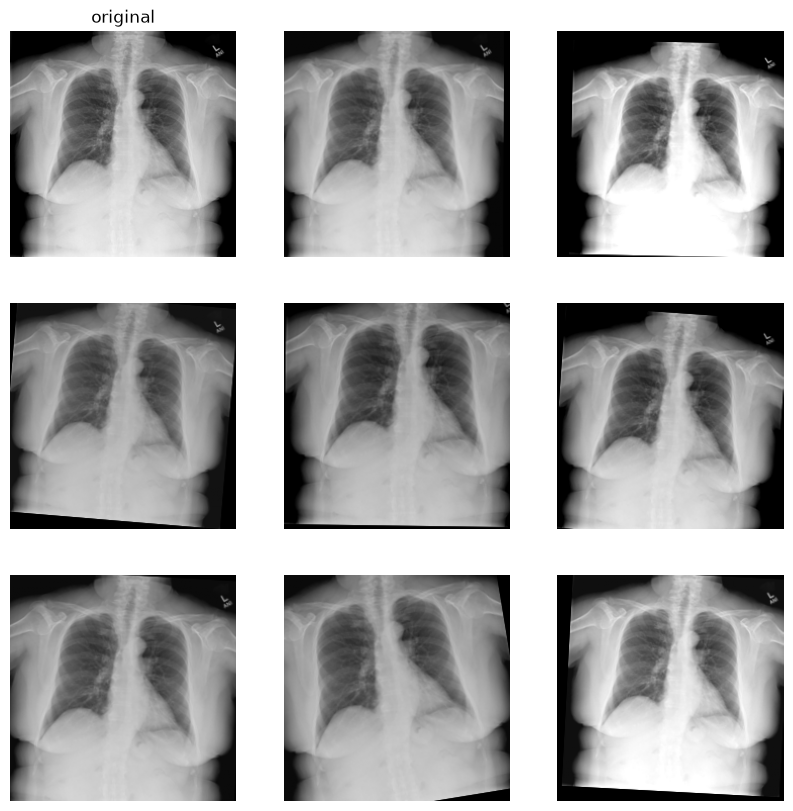

In [7]:
import matplotlib.pyplot as plt
from src.data.augment import build_train_transform
from src.data.inventory import PROJECT_ROOT
from src.data.pipeline import make_loader
from src.data.splits import load_config

cfg = load_config(PROJECT_ROOT / "configs" / "small_cnn_aug.yaml")
transform = build_train_transform(cfg["augmentation"])
# val loads in a few seconds; this is only for looking (training uses the train loader)
loader = make_loader("val", cfg["image_size"], cfg["batch_size"], transform)
dataset = loader.dataset
i = 0  # which X-ray: try a few, frontal and lateral

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
plain = dataset.images[i, 0].float() / 255  # straight from the cache, no transform
axes[0, 0].imshow(plain, cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("original")
for ax in axes.flat[1:]:
    image, _ = dataset[i]  # every call draws a new random augmentation
    ax.imshow(image[0], cmap="gray", vmin=0, vmax=1)
for ax in axes.flat:
    ax.axis("off")
